# Proyecto: Identificación de patrones de la comunidad de mamíferos en una reserva de la Selva Maya.

## Objetivo: Explorar patrones de comunidades de mamíferos y evaluar su relación con variables ambientales.

### Importación de librerias

In [58]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix)

from sklearn.model_selection import (
    train_test_split)

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster)

from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    accuracy_score)

### 1. Preparación de datos

In [59]:
registros = pd.read_csv(
    r"C:\Users\nazly\Documents\maestria\segundosemestre\cienciadedatos\proyecto\bases\registros_todo_filtrados.csv")

covs = pd.read_csv(
    r"C:\Users\nazly\Documents\maestria\segundosemestre\cienciadedatos\proyecto\bases\covariables.csv")

### 1.1 Matriz de comunidad

Se construyó la matriz de comunidad usando frecuencias relativas de detección por especie en cada cámara, para representar la composición relativa de especies en cada estación, reduciendo sesgos asociados a diferencias en abundancia total de registros entre cámaras. 

In [60]:
# abundancia por especie y estación
detecciones = (
    registros
    .groupby(["station", "species"])
    .size()
    .reset_index(name="abundancia")
)

# matriz de abundancias
matriz_comunidad = detecciones.pivot_table(
    index="station",
    columns="species",
    values="abundancia",
    fill_value=0)

# convertir a frecuencias relativas
matriz_comunidad = matriz_comunidad.div(
    matriz_comunidad.sum(axis=1),
    axis=0)

# convertir índice a columna
matriz_comunidad = matriz_comunidad.reset_index()

# quitar nombre extra
matriz_comunidad.columns.name = None

# visualizar
matriz_comunidad.head()

,station,Conepatus semistriatus,Cuniculus paca,Dasyprocta punctata,Dasypus novemcinctus,Dicotyles tajacu,Didelphis sp,Eira barbara,Galictis vittata,Leopardus pardalis,...,Mustela frenata,Nasua narica,Odocoileus pandora,Odocoileus virginianus,Panthera onca,Procyon lotor,Puma concolor,Spilogale angustifrons,Tamandua mexicana,Urocyon cinereoargenteus
0,CAM01,0.009901,0.000000,0.009901,0.000000,0.000000,0.039604,0.019802,0.0,0.000000,...,0.108911,0.108911,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.554455
1,CAM02,0.000000,0.057143,0.000000,0.028571,0.028571,0.000000,0.028571,0.0,0.085714,...,0.000000,0.171429,0.0,0.028571,0.000000,0.028571,0.000000,0.0,0.000000,0.457143
2,CAM03,0.016129,0.016129,0.000000,0.000000,0.032258,0.080645,0.016129,0.0,0.096774,...,0.096774,0.112903,0.0,0.000000,0.064516,0.000000,0.080645,0.0,0.016129,0.258065
3,CAM04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.100000,0.200000,0.0,0.400000,0.200000,0.000000,0.000000,0.0,0.000000,0.100000
4,CAM05,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,0.000000,0.0,0.000000,...,0.200000,0.000000,0.0,0.000000,0.200000,0.000000,0.200000,0.0,0.000000,0.000000


#### 1.2 Filtrado de especies raras

In [61]:
# suma total por especie
frecuencia_total = (
    matriz_comunidad
    .drop(columns="station")
    .sum())

# visualizar frecuencias
print(frecuencia_total.sort_values(
        ascending=False))

# calcular primer cuartil
q1 = frecuencia_total.quantile(0.25)

print("Primer cuartil:", q1)

# conservar especies arriba del cuartil
especies_filtradas = frecuencia_total[
    frecuencia_total > q1
].index

print(especies_filtradas)

Nasua narica                3.518613
Puma concolor               3.196700
Leopardus wiedii            2.920117
Urocyon cinereoargenteus    2.877973
Didelphis sp                2.381373
Odocoileus virginianus      2.243645
Leopardus pardalis          1.590535
Panthera onca               1.302782
Mustela frenata             0.752473
Spilogale angustifrons      0.700359
Eira barbara                0.508811
Dasypus novemcinctus        0.394553
Cuniculus paca              0.393528
Dicotyles tajacu            0.355172
Tamandua mexicana           0.257796
Conepatus semistriatus      0.232703
Odocoileus pandora          0.156566
Procyon lotor               0.125721
Dasyprocta punctata         0.067856
Galictis vittata            0.022727
dtype: float64
Primer cuartil: 0.25152251286552374
Index(['Cuniculus paca', 'Dasypus novemcinctus', 'Dicotyles tajacu',
       'Didelphis sp', 'Eira barbara', 'Leopardus pardalis',
       'Leopardus wiedii', 'Mustela frenata', 'Nasua narica',
       'Odocoileu

In [62]:
matriz_filtrada = matriz_comunidad[
    ["station"] + list(especies_filtradas)
].copy()

matriz_filtrada.head()

,station,Cuniculus paca,Dasypus novemcinctus,Dicotyles tajacu,Didelphis sp,Eira barbara,Leopardus pardalis,Leopardus wiedii,Mustela frenata,Nasua narica,Odocoileus virginianus,Panthera onca,Puma concolor,Spilogale angustifrons,Tamandua mexicana,Urocyon cinereoargenteus
0,CAM01,0.000000,0.000000,0.000000,0.039604,0.019802,0.000000,0.148515,0.108911,0.108911,0.000000,0.000000,0.000000,0.0,0.000000,0.554455
1,CAM02,0.057143,0.028571,0.028571,0.000000,0.028571,0.085714,0.085714,0.000000,0.171429,0.028571,0.000000,0.000000,0.0,0.000000,0.457143
2,CAM03,0.016129,0.000000,0.032258,0.080645,0.016129,0.096774,0.112903,0.096774,0.112903,0.000000,0.064516,0.080645,0.0,0.016129,0.258065
3,CAM04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.200000,0.400000,0.200000,0.000000,0.0,0.000000,0.100000
4,CAM05,0.000000,0.000000,0.000000,0.200000,0.000000,0.000000,0.200000,0.200000,0.000000,0.000000,0.200000,0.200000,0.0,0.000000,0.000000


#### Transformación de Hellinger
Se aplicó para ajustar el peso de las especies frecuentes frente a las raras.

In [63]:
# copiar matriz
matriz_hellinger = matriz_filtrada.copy()

# aplicar raíz cuadrada
matriz_hellinger.iloc[:,1:] = np.sqrt(
    matriz_hellinger.iloc[:,1:])

# visualizar
matriz_hellinger.head()

,station,Cuniculus paca,Dasypus novemcinctus,Dicotyles tajacu,Didelphis sp,Eira barbara,Leopardus pardalis,Leopardus wiedii,Mustela frenata,Nasua narica,Odocoileus virginianus,Panthera onca,Puma concolor,Spilogale angustifrons,Tamandua mexicana,Urocyon cinereoargenteus
0,CAM01,0.000000,0.000000,0.000000,0.199007,0.140720,0.000000,0.385376,0.330017,0.330017,0.000000,0.000000,0.000000,0.0,0.000,0.744618
1,CAM02,0.239046,0.169031,0.169031,0.000000,0.169031,0.292770,0.292770,0.000000,0.414039,0.169031,0.000000,0.000000,0.0,0.000,0.676123
2,CAM03,0.127000,0.000000,0.179605,0.283981,0.127000,0.311086,0.336011,0.311086,0.336011,0.000000,0.254000,0.283981,0.0,0.127,0.508001
3,CAM04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.316228,0.447214,0.632456,0.447214,0.000000,0.0,0.000,0.316228
4,CAM05,0.000000,0.000000,0.000000,0.447214,0.000000,0.000000,0.447214,0.447214,0.000000,0.000000,0.447214,0.447214,0.0,0.000,0.000000


### 2. Variables ambientales

Las variables ambientales incluyeron el área basal de los árboles en un radio de 20 m a partir de la cámara, área basal de los árboles frutales, cobertura de sotobosque (%), distancia a la carretera y cobertura de bosque maduro (%).

Inicialmente se contaba con múltiples escalas espaciales de cobertura forestal (100–1000 m). Sin embargo, debido a la alta correlación entre dichas variables, se calculó una variable promedio de cobertura forestal para reducir redundancia y facilitar la interpretación.

#### 2.1 Transformaciones de variables

In [64]:
# crear un promedio de % de cobertura de bosque maduro
covs["bosque_promedio"] = covs[
    [
        "bosque_100",
        "bosque_200",
        "bosque_300",
        "bosque_400",
        "bosque_500",
        "bosque_600",
        "bosque_700",
        "bosque_800",
        "bosque_900",
        "bosque_1000"
    ]
].mean(axis=1)

In [65]:
# transformación logarítmica
covs["ab_fruta_log"] = np.log1p(
    covs["ab__fruta"])

In [66]:
# variables
X_ambiental = covs[
    [
        "ab_fruta_log",
        "sotobosque",
        "carretera",
        "bosque_promedio"
    ]
]

X_ambiental.head()

,ab_fruta_log,sotobosque,carretera,bosque_promedio
0,0.176037,52.50,340.1,58.2351
1,0.144941,33.75,2469.8,47.0782
2,0.177617,26.25,3104.1,65.2580
3,0.261978,37.50,3260.4,75.5169
4,0.173210,55.00,3864.3,88.3886


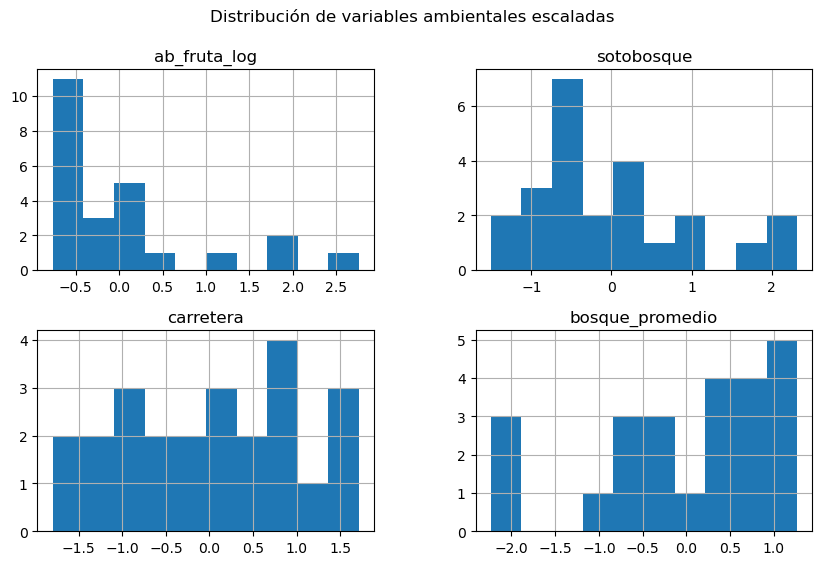

In [68]:
# estandarizar variables
scaler_ambiental = StandardScaler()

X_ambiental_scaled = scaler_ambiental.fit_transform(
    X_ambiental)

# convertir a dataframe
X_scaled_df = pd.DataFrame(
    X_ambiental_scaled,
    columns=X_ambiental.columns
)

# histogramas
X_scaled_df.hist(
    figsize=(10,6)
)

plt.suptitle(
    "Distribución de variables ambientales escaladas"
)

plt.show()

### Reducción de dimensiones - Análisis de Componentes Principales (PCA)

El PCA se usó para resumir la variación ambiental entre sitios y reducir la dimensionalidad.

In [69]:
# crear PCA
pca = PCA(n_components=3)

pca_resultados = pca.fit_transform(X_ambiental_scaled)

# varianza explicada
print(pca.explained_variance_ratio_)

[0.46217752 0.26259183 0.22042554]


Los tres primeros componentes explicaron aproximadamente el 94% de la variación ambiental total.

In [70]:
# cargar los componentes
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1","PC2","PC3"],
    index=X_ambiental.columns)

loadings.round(3)

,PC1,PC2,PC3
ab_fruta_log,0.360,0.746,-0.402
sotobosque,-0.578,0.513,-0.163
carretera,0.369,0.385,0.811
bosque_promedio,0.632,-0.181,-0.393


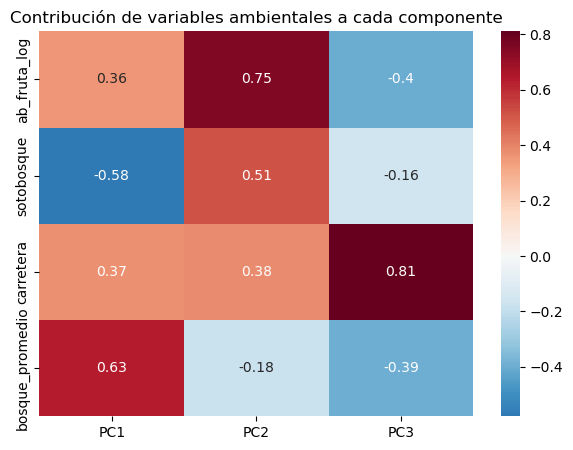

In [71]:
plt.figure(figsize=(7,5))

sns.heatmap(
    loadings,
    annot=True,
    cmap="RdBu_r",
    center=0)

plt.title(
    "Contribución de variables ambientales a cada componente")

plt.show()

PC1 explicó el 46% de la variación ambiental y estuvo asociado principalmente con la cobertura de bosque maduro y sotobosque. 

PC2 explicó el 26% de la variación y estuvo asociada principalmente con el área basal de árboles frutales y cobertura de sotobosque, sugieriendo un gradiente relacionado con recursos alimienticios y complejidad estructural. 

PC3 explicó el 22% y estuvo dominado por la distancia a la carretera, representando un grandiente de perturbación antropogénica. 

In [81]:
# data frame
pca_df = pd.DataFrame(
    pca_resultados,
    columns=["PC1","PC2","PC3"])

pca_df["station"] = covs["station"]

### 4. Agrupamiento de comunidades

#### 4.1 Clustering jerárquico

In [82]:
# matriz para clusters
# seleccionar especies
X_comunidad = matriz_hellinger[
    list(especies_filtradas)]

In [83]:
# escalar matriz comunitaria
scaler_comunidad = StandardScaler()

X_comunidad_scaled = scaler_comunidad.fit_transform(
    X_comunidad)

In [84]:
# clustering
Z = linkage(
    X_comunidad_scaled,
    method="ward")

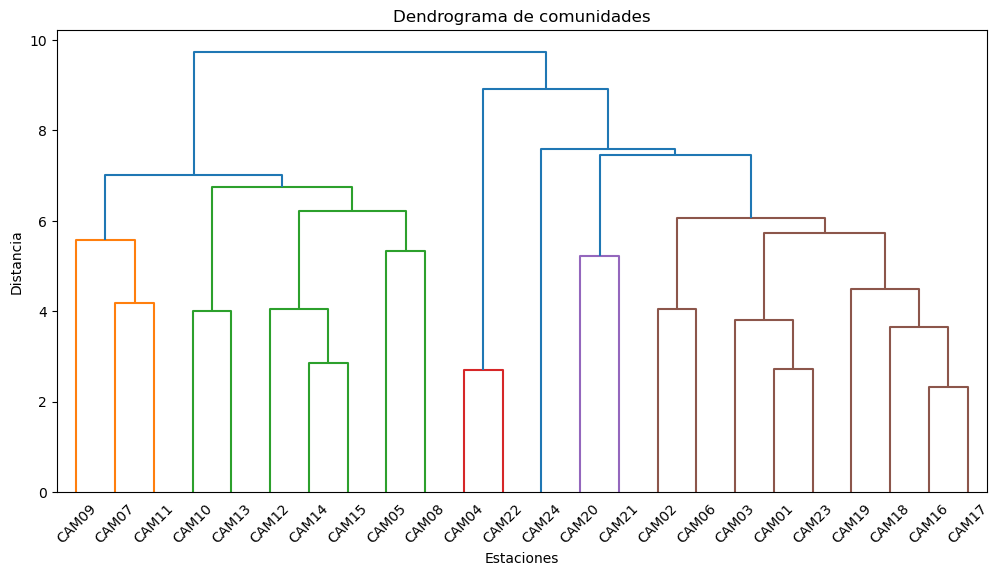

In [85]:
# dendrograma
plt.figure(figsize=(12,6))

dendrogram(
    Z,
    labels=matriz_hellinger["station"].values)

plt.title("Dendrograma de comunidades")

plt.xlabel("Estaciones")
plt.ylabel("Distancia")

plt.show()

El clustering jerárquico mostró la existencia de grupos con composición relativamente similar.

In [86]:
# definir clusters
clusters = fcluster(
    Z,
    t=3,
    criterion="maxclust")

pca_df["cluster"] = clusters

# agregar clusters
matriz_hellinger["cluster"] = clusters

# revisar tamaños
print(
    matriz_hellinger["cluster"].value_counts() )
matriz_hellinger[
    ["station", "cluster"] ]

cluster
3    12
1    10
2     2
Name: count, dtype: int64


,station,cluster
0,CAM01,3
1,CAM02,3
2,CAM03,3
3,CAM04,2
4,CAM05,1
5,CAM06,3
6,CAM07,1
7,CAM08,1
8,CAM09,1
9,CAM10,1


#### 4.2 Visualización sobre PCA

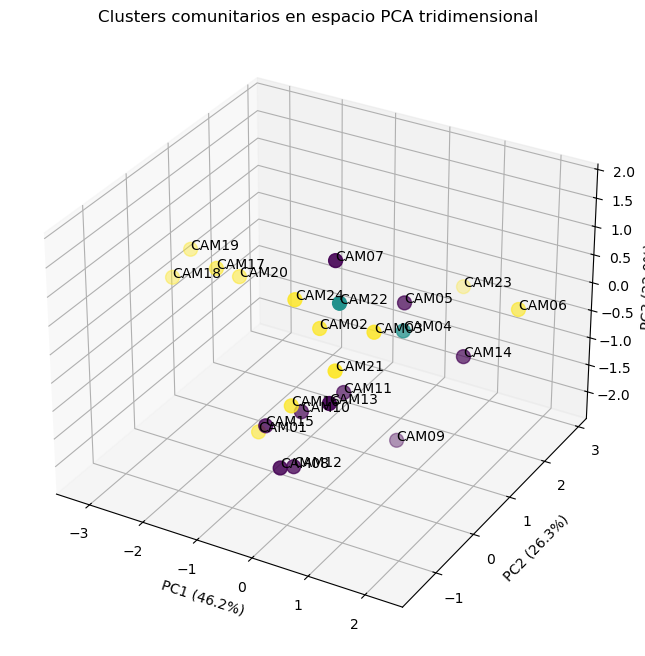

In [79]:
fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(
    111,
    projection="3d")

scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    pca_df["PC3"],
    c=pca_df["cluster"],
    s=100)

# nombres de cámaras
for i in range(len(pca_df)):

    ax.text(
        pca_df["PC1"][i],
        pca_df["PC2"][i],
        pca_df["PC3"][i],
        pca_df["station"][i]
    )

ax.set_xlabel(
    f"PC1 ({var_exp[0]*100:.1f}%)")

ax.set_ylabel(
    f"PC2 ({var_exp[1]*100:.1f}%)")

ax.set_zlabel(
    f"PC3 ({var_exp[2]*100:.1f}%)")

ax.set_title(
    "Clusters comunitarios en espacio PCA tridimensional")

plt.show()

### 5. Aprendizaje supervisado

#### 5.1 Random forest

In [87]:
# variables predictoras
X_modelo = X_ambiental.copy()

# variable respuesta
y = clusters

# entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_modelo,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y )

# modelo
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42 )

# entrenar
rf.fit(
    X_train,
    y_train )

# predicciones
y_pred_rf = rf.predict(
    X_test)

# evaluación
print(
    classification_report(
        y_test,
        y_pr           precision    recall  f1-score   support

           1       0.60      1.00      0.75         3
           2       0.00      0.00      0.00         1
           3       1.00      0.75      0.86         4

    accuracy                           0.75         8
   macro avg       0.53      0.58      0.54         8
weighted avg       0.72      0.75      0.71         8ed_rf,
        zero_division=0 ) )

              precision    recall  f1-score   support

           1       0.60      1.00      0.75         3
           2       0.00      0.00      0.00         1
           3       1.00      0.75      0.86         4

    accuracy                           0.75         8
   macro avg       0.53      0.58      0.54         8
weighted avg       0.72      0.75      0.71         8



Random forest clasificó adecuadamente los dos grupos principales, teniendo una exactitud global de 75%. El desempeño fue menor para el cluster 2 probablemente por el número reducido de sitios que lo conformaron. 

### 5.2 Máquina de soporte vectorial

Para evaluar la capacidad de las variables ambientales para prededcir los grupos.

In [88]:
svm = SVC(
    kernel="rbf",
    C=1,
    gamma="scale",
    random_state=42)

svm.fit(
    X_train,
    y_train)

y_pred_svm = svm.predict(
    X_test)

print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

acc_svm = accuracy_score(
    y_test,
    y_pred_svm)

print(
    "Accuracy:",
    acc_svm)

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         3
           2       0.00      0.00      0.00         1
           3       0.50      1.00      0.67         4

    accuracy                           0.50         8
   macro avg       0.17      0.33      0.22         8
weighted avg       0.25      0.50      0.33         8

Accuracy: 0.5


In [89]:
acc_rf = accuracy_score(
    y_test,
    y_pred_rf
)

comparacion = pd.DataFrame({
    "Modelo":[
        "Random Forest",
        "SVM"
    ],
    "Accuracy":[
        acc_rf,
        acc_svm
    ]
})

comparacion

,Modelo,Accuracy
0,Random Forest,0.75
1,SVM,0.50


Random forest mostró un mejor desempeño que SVM para predecir los grupos.

In [91]:
# importancia de variables
importancias = pd.DataFrame({

    "Variable": X_modelo.columns,

    "Importancia": rf.feature_importances_
})

# ordenar
importancias = importancias.sort_values(
    by="Importancia",
    ascending=False)

print(importancias)

          Variable  Importancia
3  bosque_promedio     0.345065
2        carretera     0.309202
1       sotobosque     0.246184
0     ab_fruta_log     0.099549


La cobertura promedio de bosque maduro fue la variable ambiental más importante para diferenciar comunidades de mamíferos. La distancia a carretera y la cobertura también mostraron contribución importantes. Lo que sugiere que la calidad y cantidad de hábitat son factores relevantes para explicar los patrones de agrupamiento de la comunidad de mamíferos observada en la reserva.